# 06 · Files & Data Formats

**Module 01 — Python Foundations for Data Science**

---

## What you will learn

1. `pathlib` — the modern way to handle paths, and why string concatenation breaks.
2. Context managers (`with`) and how to write your own.
3. CSV: the format everyone uses and nobody reads the spec for.
4. JSON: nested data, and the types it silently cannot represent.
5. **Parquet**: columnar storage, and why it is 10× smaller and 50× faster than CSV.
6. A measured comparison so you can choose a format on evidence.

**Estimated time:** 75 minutes

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd

from dstoolkit import format_bytes, setup_plot_style

setup_plot_style()

## 1. `pathlib` — stop building paths with strings

String concatenation for paths is fragile: it breaks across operating systems,
double-separators creep in, and there is no validation. `pathlib.Path` treats a
path as a structured object.

In [2]:
def find_repo_root(marker: str = "pyproject.toml") -> Path:
    """Walk upward from the working directory until `marker` is found.

    Counting `.parent` calls breaks the moment a notebook moves one level.
    Searching for a file that only exists at the project root does not — this is
    the pattern to reuse in your own projects.
    """
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / marker).exists():
            return candidate
    raise FileNotFoundError(f"no {marker} found above {Path.cwd()}")


# The `/` operator joins path components, using the correct separator for the OS.
REPO_ROOT = find_repo_root()
DATA_DIR = REPO_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"

# `parents=True` creates intermediate directories; `exist_ok=True` makes the call
# idempotent, so re-running the notebook is safe.
RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print(f"repo root : {REPO_ROOT}")
print(f"raw data  : {RAW_DIR}")
print(f"exists?   : {RAW_DIR.exists()}")

repo root : /Users/usuario/Desktop/CoursePythonStatistics
raw data  : /Users/usuario/Desktop/CoursePythonStatistics/data/raw
exists?   : True


In [3]:
sample = RAW_DIR / "customers_2024_q1.csv"

# Paths decompose into named parts — no string slicing required.
print(f"full path : {sample}")
print(f".name     : {sample.name}")
print(f".stem     : {sample.stem}")
print(f".suffix   : {sample.suffix}")
print(f".parent   : {sample.parent}")

# Deriving a related path is one call, not string surgery.
print(f"\nas parquet : {sample.with_suffix('.parquet').name}")
print(f"in processed : {(PROCESSED_DIR / sample.name).relative_to(REPO_ROOT)}")

full path : /Users/usuario/Desktop/CoursePythonStatistics/data/raw/customers_2024_q1.csv
.name     : customers_2024_q1.csv
.stem     : customers_2024_q1
.suffix   : .csv
.parent   : /Users/usuario/Desktop/CoursePythonStatistics/data/raw

as parquet : customers_2024_q1.parquet
in processed : data/processed/customers_2024_q1.csv


### Finding files

`glob` matches one directory level; `rglob` recurses. Both return generators, so
they stay cheap even on huge directory trees.

In [4]:
# Every notebook source in this module.
scripts_dir = REPO_ROOT / "modules" / "01-python-foundations" / "scripts"
found = sorted(scripts_dir.glob("*.py"))

print(f"{len(found)} notebook sources found:")
for path in found:
    size = format_bytes(path.stat().st_size)
    print(f"  {path.name:<52} {size:>10}")

9 notebook sources found:
  01_course_introduction_and_setup.py                    19.3 KiB
  02_python_fundamentals.py                              24.1 KiB
  03_data_structures.py                                  23.7 KiB
  04_functions_and_functional_programming.py             23.2 KiB
  05_object_oriented_programming.py                      21.7 KiB
  06_files_and_data_formats.py                           21.7 KiB
  07_errors_logging_and_testing.py                       24.6 KiB
  08_module_project.py                                   33.6 KiB
  09_exercise_solutions.py                               51.8 KiB


> [!TIP]
> Define your paths **once**, near the top of a notebook, relative to a project
> root you compute rather than hard-code. Absolute paths like
> `/Users/ana/Desktop/project/data.csv` are the single most common reason a
> colleague cannot run your notebook.

## 2. Context managers

A file must be closed. Leaving files open leaks operating-system handles and —
worse for data work — buffered writes may never reach disk.

The `with` statement guarantees cleanup **even if an exception is raised**.

In [5]:
demo_file = RAW_DIR / "demo.txt"

# ✘ Fragile: if the write raises, close() never runs.
handle = open(demo_file, "w", encoding="utf-8")
handle.write("first line\n")
handle.close()

# ✔ Correct: closed automatically, exception or not.
with open(demo_file, "a", encoding="utf-8") as f:
    f.write("second line\n")

print(f"file closed automatically : {f.closed}")
print(f"contents:\n{demo_file.read_text(encoding='utf-8')}")

file closed automatically : True
contents:
first line
second line



For simple whole-file reads and writes, `pathlib` is shorter still:

In [6]:
demo_file.write_text("overwritten by pathlib\n", encoding="utf-8")
print(demo_file.read_text(encoding="utf-8"))

overwritten by pathlib



### Writing your own context manager

Any setup/teardown pair is a candidate. `@contextmanager` turns a generator into
one: everything before `yield` is setup, everything after is guaranteed teardown.

In [7]:
from contextlib import contextmanager


@contextmanager
def atomic_write(path: Path, encoding: str = "utf-8"):
    """Write to a temporary file, then move it into place only on success.

    This prevents a half-written file from replacing a good one when the process
    crashes mid-write — a real hazard for scheduled data jobs, where a truncated
    output silently poisons everything downstream.
    """
    temp_path = path.with_suffix(path.suffix + ".tmp")
    handle = temp_path.open("w", encoding=encoding)
    try:
        yield handle              # the body of the `with` block runs here
    except Exception:
        handle.close()
        temp_path.unlink(missing_ok=True)   # clean up the partial file
        raise                                # re-raise so the caller still sees it
    else:
        handle.close()
        temp_path.replace(path)   # atomic on POSIX: readers see old or new, never partial


target = RAW_DIR / "atomic_demo.txt"

with atomic_write(target) as f:
    f.write("this write succeeded\n")
print(f"success  : {target.read_text().strip()!r}")

# Now simulate a crash halfway through.
try:
    with atomic_write(target) as f:
        f.write("this will be discarded\n")
        raise RuntimeError("simulated crash")
except RuntimeError as exc:
    print(f"crash    : {exc}")

print(f"original preserved : {target.read_text().strip()!r}")
print(f"no .tmp left behind: {not target.with_suffix('.txt.tmp').exists()}")

success  : 'this write succeeded'
crash    : simulated crash
original preserved : 'this write succeeded'
no .tmp left behind: True


## 3. Build a realistic dataset

Let us create something big enough for the format comparison to mean something.

In [8]:
rng = np.random.default_rng(seed=42)
N_ROWS = 200_000

orders = pd.DataFrame({
    "order_id": np.arange(1, N_ROWS + 1),
    "customer_id": rng.integers(1, 20_000, size=N_ROWS),
    "order_date": pd.to_datetime("2024-01-01")
                  + pd.to_timedelta(rng.integers(0, 365, size=N_ROWS), unit="D"),
    # Low-cardinality strings — the case where columnar formats shine.
    "channel": rng.choice(["organic", "paid", "referral", "email"], size=N_ROWS),
    "country": rng.choice(["BR", "US", "PT", "ES", "MX"], size=N_ROWS),
    "amount": np.round(rng.lognormal(4.0, 0.8, size=N_ROWS), 2),
    "quantity": rng.integers(1, 10, size=N_ROWS),
    "is_gift": rng.choice([True, False], size=N_ROWS, p=[0.15, 0.85]),
})

print(f"{len(orders):,} rows × {orders.shape[1]} columns")
print(f"in-memory size : {format_bytes(orders.memory_usage(deep=True).sum())}")
orders.head()

200,000 rows × 8 columns


in-memory size : 12.4 MiB


,order_id,customer_id,order_date,channel,country,amount,quantity,is_gift
0,1,1785,2024-12-29,email,ES,68.05,7,False
1,2,15479,2024-12-08,paid,PT,48.10,4,False
2,3,13091,2024-12-17,email,BR,79.88,1,False
3,4,8778,2024-12-11,paid,PT,161.07,7,True
4,5,8660,2024-11-18,paid,MX,44.36,6,False


In [9]:
# Always check dtypes after building or loading a DataFrame. A numeric column
# that arrived as `object` is the single most common cause of a slow, wrong
# analysis — and it is invisible in `.head()`.
orders.dtypes

order_id                int64
customer_id             int64
order_date     datetime64[us]
channel                   str
country                   str
amount                float64
quantity                int64
is_gift                  bool
dtype: object

## 4. CSV — universal, and full of traps

CSV is a *convention*, not a strict standard. Everyone supports it, which is its
only real advantage.

In [10]:
csv_path = RAW_DIR / "orders.csv"

# `index=False` matters: without it pandas writes the RangeIndex as an unnamed
# first column, which reappears as "Unnamed: 0" the next time anyone reads it.
orders.to_csv(csv_path, index=False)

print(f"written : {csv_path.name}  ({format_bytes(csv_path.stat().st_size)})")
print("\nfirst three lines:")
with csv_path.open(encoding="utf-8") as f:
    for _ in range(3):
        print(f"  {f.readline().rstrip()}")

written : orders.csv  (8.9 MiB)

first three lines:
  order_id,customer_id,order_date,channel,country,amount,quantity,is_gift
  1,1785,2024-12-29,email,ES,68.05,7,False
  2,15479,2024-12-08,paid,PT,48.1,4,False


### What CSV loses

A CSV file is *just text*. Every type annotation is discarded on write, and
pandas must guess them all back on read.

In [11]:
reloaded = pd.read_csv(csv_path)

comparison = pd.DataFrame({
    "original": orders.dtypes.astype(str),
    "after CSV round-trip": reloaded.dtypes.astype(str),
})
comparison["preserved"] = np.where(
    comparison["original"] == comparison["after CSV round-trip"], "✔", "✘ LOST"
)
comparison

,original,after CSV round-trip,preserved
order_id,int64,int64,✔
customer_id,int64,int64,✔
order_date,datetime64[us],str,✘ LOST
channel,str,str,✔
country,str,str,✔
amount,float64,float64,✔
quantity,int64,int64,✔
is_gift,bool,bool,✔


> [!WARNING]
> `order_date` came back as a plain `object` (string). Any date arithmetic on
> it will now fail or, worse, sort lexicographically — putting `2024-10-01`
> before `2024-2-01`.

The fix is to tell pandas what you expect rather than letting it guess:

In [12]:
reloaded_typed = pd.read_csv(
    csv_path,
    parse_dates=["order_date"],
    # An explicit dtype map is faster and safer than inference. `category` also
    # cuts memory dramatically for repeated strings.
    dtype={
        "order_id": "int32",
        "customer_id": "int32",
        "channel": "category",
        "country": "category",
        "quantity": "int8",
    },
)

print(reloaded_typed.dtypes)
print(f"\nmemory with explicit dtypes : "
      f"{format_bytes(reloaded_typed.memory_usage(deep=True).sum())}")
print(f"memory with inferred dtypes : "
      f"{format_bytes(reloaded.memory_usage(deep=True).sum())}")

order_id                int32
customer_id             int32
order_date     datetime64[us]
channel              category
country              category
amount                float64
quantity                 int8
is_gift                  bool
dtype: object

memory with explicit dtypes : 5.3 MiB
memory with inferred dtypes : 14.3 MiB


### The other CSV traps

| Trap | Symptom | Fix |
| :--- | :--- | :--- |
| Wrong encoding | `UnicodeDecodeError` | `encoding="latin-1"` or `"cp1252"` |
| European decimals | `1.234,56` read as text | `decimal=","`, `sep=";"` |
| Leading zeros | `00123` → `123` | `dtype={"zip": str}` |
| Big numeric IDs | precision lost above 2⁵³ | `dtype={"id": str}` |
| `"NA"`, `"N/A"`, `"-"` | not recognised as missing | `na_values=["NA", "-"]` |
| File larger than RAM | `MemoryError` | `chunksize=100_000` |

In [13]:
# Reading in chunks: the CSV equivalent of the generator pattern from notebook 04.
total = 0.0
n_chunks = 0

for chunk in pd.read_csv(csv_path, chunksize=50_000, usecols=["amount"]):
    total += chunk["amount"].sum()
    n_chunks += 1

print(f"processed {n_chunks} chunks without loading the file at once")
print(f"total amount : ${total:,.2f}")
print(f"matches full read : {np.isclose(total, orders['amount'].sum())}")

processed 4 chunks without loading the file at once
total amount : $14,997,711.24
matches full read : True


## 5. JSON — nested data

JSON handles hierarchy, which CSV cannot. It is the format of essentially every
web API you will pull data from.

In [14]:
api_response = {
    "request_id": "req_8a2f",
    "meta": {"page": 1, "total_pages": 12, "generated_at": "2024-03-15T10:00:00Z"},
    "results": [
        {"id": 1, "name": "Ana", "tags": ["premium", "eu"], "score": 9.4},
        {"id": 2, "name": "Bruno", "tags": [], "score": None},
    ],
}

json_path = RAW_DIR / "api_response.json"

with json_path.open("w", encoding="utf-8") as f:
    # `indent` makes it human-readable and diffable; `ensure_ascii=False` keeps
    # accented characters as themselves rather than \uXXXX escapes.
    json.dump(api_response, f, indent=2, ensure_ascii=False)

print(json_path.read_text(encoding="utf-8")[:320])

{
  "request_id": "req_8a2f",
  "meta": {
    "page": 1,
    "total_pages": 12,
    "generated_at": "2024-03-15T10:00:00Z"
  },
  "results": [
    {
      "id": 1,
      "name": "Ana",
      "tags": [
        "premium",
        "eu"
      ],
      "score": 9.4
    },
    {
      "id": 2,
      "name": "Bruno",
      "t


### Flattening nested JSON for analysis

`pd.json_normalize` turns nested structures into a flat table — the bridge
between an API response and a DataFrame.

In [15]:
flat = pd.json_normalize(
    api_response,
    record_path="results",       # the list to turn into rows
    meta=["request_id", ["meta", "page"]],   # fields to broadcast onto every row
)
flat

,id,name,tags,score,request_id,meta.page
0,1,Ana,"[premium, eu]",9.4,req_8a2f,1
1,2,Bruno,[],NaN,req_8a2f,1


> [!WARNING]
> **JSON has no date type and no NaN.** Dates become strings, and `NaN`/`Infinity`
> are not valid JSON — Python's `json` module writes them anyway, producing files
> that other languages reject.

In [16]:
problematic = {"value": float("nan"), "big": float("inf")}

# Python happily writes invalid JSON by default…
print(f"default        : {json.dumps(problematic)}")

# …but this is what a strict parser elsewhere will do with it:
try:
    json.dumps(problematic, allow_nan=False)
except ValueError as exc:
    print(f"strict mode    : ValueError — {exc}")

print(f"\nSafe: write null instead → "
      f"{json.dumps({'value': None, 'big': None})}")

default        : {"value": NaN, "big": Infinity}
strict mode    : ValueError — Out of range float values are not JSON compliant: nan

Safe: write null instead → {"value": null, "big": null}


## 6. Parquet — the format for data science

Parquet stores data **by column** rather than by row, with per-column
compression and an embedded schema.

```text
CSV (row-oriented)              Parquet (column-oriented)
─────────────────────           ─────────────────────────
1,organic,BR,54.20              order_id : [1, 2, 3, …]      ← one type, compresses well
2,paid,US,120.00                channel  : [organic, paid, …] ← dictionary-encoded
3,paid,BR,17.50                 country  : [BR, US, BR, …]
                                amount   : [54.20, 120.00, …]
```

Three consequences follow directly from that layout:

1. **Compression is far better** — a column holds one type, often with few distinct values.
2. **Reading a subset of columns is nearly free** — the other columns are never touched.
3. **The schema is stored in the file** — dtypes survive the round trip exactly.

In [17]:
parquet_path = RAW_DIR / "orders.parquet"
orders.to_parquet(parquet_path, engine="pyarrow", compression="snappy", index=False)

parquet_reloaded = pd.read_parquet(parquet_path)

print(f"written : {parquet_path.name}  ({format_bytes(parquet_path.stat().st_size)})")
print(f"\ndtypes identical to the original : "
      f"{orders.dtypes.equals(parquet_reloaded.dtypes)}")
print(f"data identical                   : "
      f"{orders.equals(parquet_reloaded)}")

written : orders.parquet  (2.4 MiB)

dtypes identical to the original : True
data identical                   : True


### Column pruning — the feature that changes how you work

Reading two columns from a 50-column Parquet file costs roughly what those two
columns cost. With CSV you must parse every byte of every row regardless.

In [18]:
import time

start = time.perf_counter()
_ = pd.read_parquet(parquet_path, columns=["channel", "amount"])
parquet_partial = time.perf_counter() - start

start = time.perf_counter()
_ = pd.read_parquet(parquet_path)
parquet_full = time.perf_counter() - start

start = time.perf_counter()
_ = pd.read_csv(csv_path, usecols=["channel", "amount"])
csv_partial = time.perf_counter() - start

print(f"parquet, 2 of 8 columns : {parquet_partial * 1000:7.1f} ms")
print(f"parquet, all 8 columns  : {parquet_full * 1000:7.1f} ms")
print(f"csv,     2 of 8 columns : {csv_partial * 1000:7.1f} ms")
print(f"\n→ parquet reads the 2-column subset "
      f"{csv_partial / parquet_partial:.0f}× faster than CSV")

parquet, 2 of 8 columns :    12.3 ms
parquet, all 8 columns  :    17.6 ms
csv,     2 of 8 columns :    98.8 ms

→ parquet reads the 2-column subset 8× faster than CSV


## 7. Measured comparison

Enough assertion — let us measure size and speed across the three formats.

In [19]:
def benchmark(name: str, write_fn, read_fn, path: Path) -> dict:
    """Time a write and a read, and record the resulting file size."""
    start = time.perf_counter()
    write_fn(path)
    write_time = time.perf_counter() - start

    start = time.perf_counter()
    read_fn(path)
    read_time = time.perf_counter() - start

    return {
        "format": name,
        "size_mb": path.stat().st_size / 1024**2,
        "write_s": write_time,
        "read_s": read_time,
    }


results = [
    benchmark(
        "CSV",
        lambda p: orders.to_csv(p, index=False),
        lambda p: pd.read_csv(p, parse_dates=["order_date"]),
        RAW_DIR / "bench.csv",
    ),
    benchmark(
        "JSON",
        lambda p: orders.to_json(p, orient="records", date_format="iso"),
        lambda p: pd.read_json(p, orient="records"),
        RAW_DIR / "bench.json",
    ),
    benchmark(
        "Parquet",
        lambda p: orders.to_parquet(p, compression="snappy", index=False),
        lambda p: pd.read_parquet(p),
        RAW_DIR / "bench.parquet",
    ),
]

bench = pd.DataFrame(results).set_index("format")
bench.round(3)

,size_mb,write_s,read_s
format,,,
CSV,8.936,0.673,0.249
JSON,29.726,0.601,1.436
Parquet,2.396,0.100,0.054


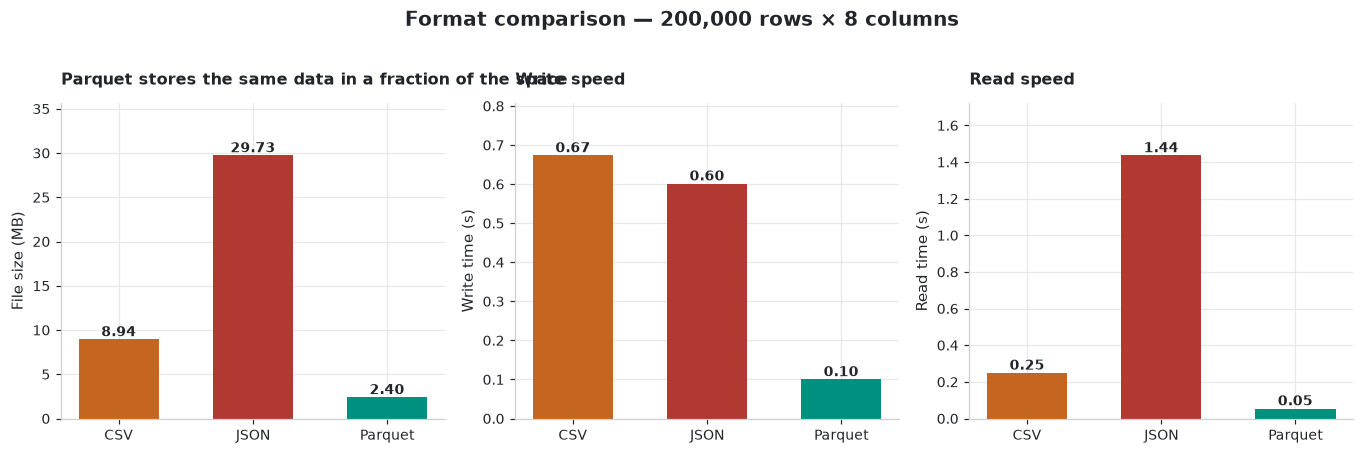

In [20]:
import matplotlib.pyplot as plt

from dstoolkit.plotting import COLORS

fig, axes = plt.subplots(1, 3, figsize=(12.5, 4))

panels = [
    ("size_mb", "File size (MB)", "Parquet stores the same data in a fraction of the space"),
    ("write_s", "Write time (s)", "Write speed"),
    ("read_s", "Read time (s)", "Read speed"),
]

# One colour per format, held constant across all three panels so the reader
# tracks a format by colour rather than by position.
format_colors = {
    "CSV": COLORS["accent"],
    "JSON": COLORS["danger"],
    "Parquet": COLORS["teal"],
}
colors = [format_colors[f] for f in bench.index]

for ax, (column, ylabel, title) in zip(axes, panels, strict=True):
    values = bench[column]
    ax.bar(bench.index, values, color=colors, width=0.6)
    ax.set_ylabel(ylabel)
    ax.set_title(title if column == "size_mb" else title, fontsize=10.5)
    ax.set_ylim(0, values.max() * 1.2)

    # Direct labels: with three bars a legend would be redundant ink.
    for i, value in enumerate(values):
        ax.text(i, value, f"{value:.2f}", ha="center", va="bottom",
                fontsize=9, fontweight="bold")

fig.suptitle(f"Format comparison — {len(orders):,} rows × {orders.shape[1]} columns",
             fontsize=13, y=1.02)
fig.tight_layout()
plt.show()

In [21]:
csv_row = bench.loc["CSV"]
pq_row = bench.loc["Parquet"]

print(f"Parquet vs CSV on this dataset:")
print(f"  {csv_row['size_mb'] / pq_row['size_mb']:5.1f}× smaller on disk")
print(f"  {csv_row['write_s'] / pq_row['write_s']:5.1f}× faster to write")
print(f"  {csv_row['read_s'] / pq_row['read_s']:5.1f}× faster to read")
print(f"  and dtypes survive the round trip exactly")

Parquet vs CSV on this dataset:
    3.7× smaller on disk
    6.7× faster to write
    4.6× faster to read
  and dtypes survive the round trip exactly


## 8. Choosing a format

| Format | Use it when | Avoid it when |
| :--- | :--- | :--- |
| **CSV** | A human must open it; you are exchanging with a non-technical team | Data is large, typed, or nested |
| **JSON** | Nested/hierarchical data; API payloads; configuration | Tabular data at any real scale |
| **Parquet** | **Any analytical dataset you control** — the default | A human needs to read it in a text editor |
| **Pickle** | Short-lived Python-only caching | *Anything shared or long-lived* — see below |
| **Feather** | Very fast temporary interchange between pandas/R sessions | Long-term archival |

> [!WARNING]
> **Never load a pickle from an untrusted source.** Unpickling executes arbitrary
> code by design, so a malicious `.pkl` is simply a program you agreed to run.
> Pickles are also fragile across library versions: a file written with
> pandas 2.x may not load under 3.x.

### The convention this course follows

```text
data/raw/         ← exactly as received, never modified (CSV, JSON, whatever arrived)
data/processed/   ← cleaned, typed, analysis-ready  → always Parquet
```

In [22]:
# Demonstrate the convention: read raw, clean, write processed.
clean = (
    pd.read_csv(csv_path, parse_dates=["order_date"])
    .assign(
        channel=lambda df: df["channel"].astype("category"),
        country=lambda df: df["country"].astype("category"),
        revenue=lambda df: (df["amount"] * df["quantity"]).round(2),
    )
    .loc[lambda df: df["amount"] > 0]      # drop non-positive amounts
)

output_path = PROCESSED_DIR / "orders_clean.parquet"
clean.to_parquet(output_path, index=False)

print(f"wrote {len(clean):,} clean rows → {output_path.relative_to(REPO_ROOT)}")
print(f"size  : {format_bytes(output_path.stat().st_size)}")
clean.head(3)

wrote 200,000 clean rows → data/processed/orders_clean.parquet
size  : 3.1 MiB


,order_id,customer_id,order_date,channel,country,amount,quantity,is_gift,revenue
0,1,1785,2024-12-29,email,ES,68.05,7,False,476.35
1,2,15479,2024-12-08,paid,PT,48.10,4,False,192.40
2,3,13091,2024-12-17,email,BR,79.88,1,False,79.88


In [23]:
# Tidy up the benchmark artefacts so the repo stays clean.
for temp in ["bench.csv", "bench.json", "bench.parquet", "demo.txt", "atomic_demo.txt"]:
    (RAW_DIR / temp).unlink(missing_ok=True)

print("temporary files removed")
print(f"remaining in data/raw : {sorted(p.name for p in RAW_DIR.glob('*'))}")

temporary files removed
remaining in data/raw : ['.gitkeep', 'api_response.json', 'nordwind_customers.json', 'nordwind_orders.csv', 'orders.csv', 'orders.parquet']


## 9. Exercises

### Exercise 6.1 — Path manipulation

Given `Path("data/raw/sales_2024_q1.csv")`, use `pathlib` (no string methods on
the full path) to produce:

1. `data/processed/sales_2024_q1.parquet`
2. The year and quarter as separate strings, extracted from the stem.
3. A sibling path `sales_2024_q1_backup.csv`.

### Exercise 6.2 — Diagnose a broken CSV

Write a file containing:

```text
id;name;price;date
001;Café;1.234,56;15/03/2024
002;Naïve;987,65;16/03/2024
```

Then read it into a DataFrame with the correct dtypes: `id` as a string with its
leading zeros, `price` as a float, `date` as a datetime.

### Exercise 6.3 — Nested JSON

Flatten this into one row per item, carrying the order fields onto each row:

```python
{"order_id": 1, "customer": {"name": "Ana", "city": "SP"},
 "items": [{"sku": "A", "qty": 2}, {"sku": "B", "qty": 1}]}
```

### Exercise 6.4 — Prove the column-pruning claim

Build a DataFrame with 50 columns and 500 000 rows. Time reading **one** column
from Parquet versus from CSV. Explain the ratio in terms of the storage layout.

### Exercise 6.5 — Safe writing

Extend `atomic_write` so it also takes a `backup: bool` argument that keeps the
previous version as `<name>.bak` before replacing it.

## Key takeaways

- Use **`pathlib`**, never string concatenation. Compute a project root; never
  hard-code absolute paths.
- **Always use `with`** for files — it closes them even when an exception fires.
- **CSV loses every dtype.** Pass `parse_dates` and an explicit `dtype` map, and
  always write with `index=False`.
- **JSON has no date and no NaN type.** Convert deliberately before writing.
- **Parquet is the default for analytical data**: smaller, faster, self-describing,
  and it supports column pruning.
- **Never unpickle untrusted data** — it executes arbitrary code.
- Convention: `data/raw/` is immutable input; `data/processed/` is Parquet output.

---

**Next:** [07 · Errors, Logging & Testing](07_errors_logging_and_testing.ipynb) —
making a pipeline that fails loudly instead of silently.